<a href="https://colab.research.google.com/github/takakei510/tetra-peg-network/blob/main/notebooks/H2_report_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H₂報告図の再作図
Driveに置いた小さい集計CSVから図を作ります。大規模原データは読みません。
このフォルダ一式をDriveの `MyDrive/tetra-peg-network/h2_report` に配置してください。CPUで十分です。

In [ ]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## 保存場所
実際のDriveフォルダが異なる場合はROOTだけ書き換えます。ノートPCのGドライブではなく、Colab側のパスです。

In [ ]:
from pathlib import Path
ROOT = Path("/content/drive/MyDrive/tetra-peg-network/h2_report")
assert (ROOT / "size_relation.csv").is_file(), "ROOTを実際の配置先に変更してください"
assert (ROOT / "plot_report.py").is_file()
print("入力:", ROOT / "size_relation.csv")


入力: /content/drive/MyDrive/tetra-peg-network/h2_report/size_relation.csv


## 日本語フォント
Colabの実行環境に導入します。ノートPCへのインストールではありません。

In [ ]:
import subprocess
subprocess.run(["apt-get", "-qq", "update"], check=True)
subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)


CompletedProcess(args=['apt-get', '-qq', 'install', '-y', 'fonts-noto-cjk'], returncode=0)

## 図を出力
データは読み取りのみ。出力はDrive内のfigures_colabへ保存します。既存の同名図は更新します。

In [ ]:
import sys
subprocess.run([sys.executable, str(ROOT / "plot_report.py"), "--input", str(ROOT / "size_relation.csv"), "--output", str(ROOT / "figures_colab"), "--L", "128", "--phi", "0.40", "0.47", "0.55"], check=True)


CompletedProcess(args=['/usr/bin/python3', '/content/drive/MyDrive/tetra-peg-network/h2_report/plot_report.py', '--input', '/content/drive/MyDrive/tetra-peg-network/h2_report/size_relation.csv', '--output', '/content/drive/MyDrive/tetra-peg-network/h2_report/figures_colab', '--L', '128', '--phi', '0.40', '0.47', '0.55'], returncode=0)

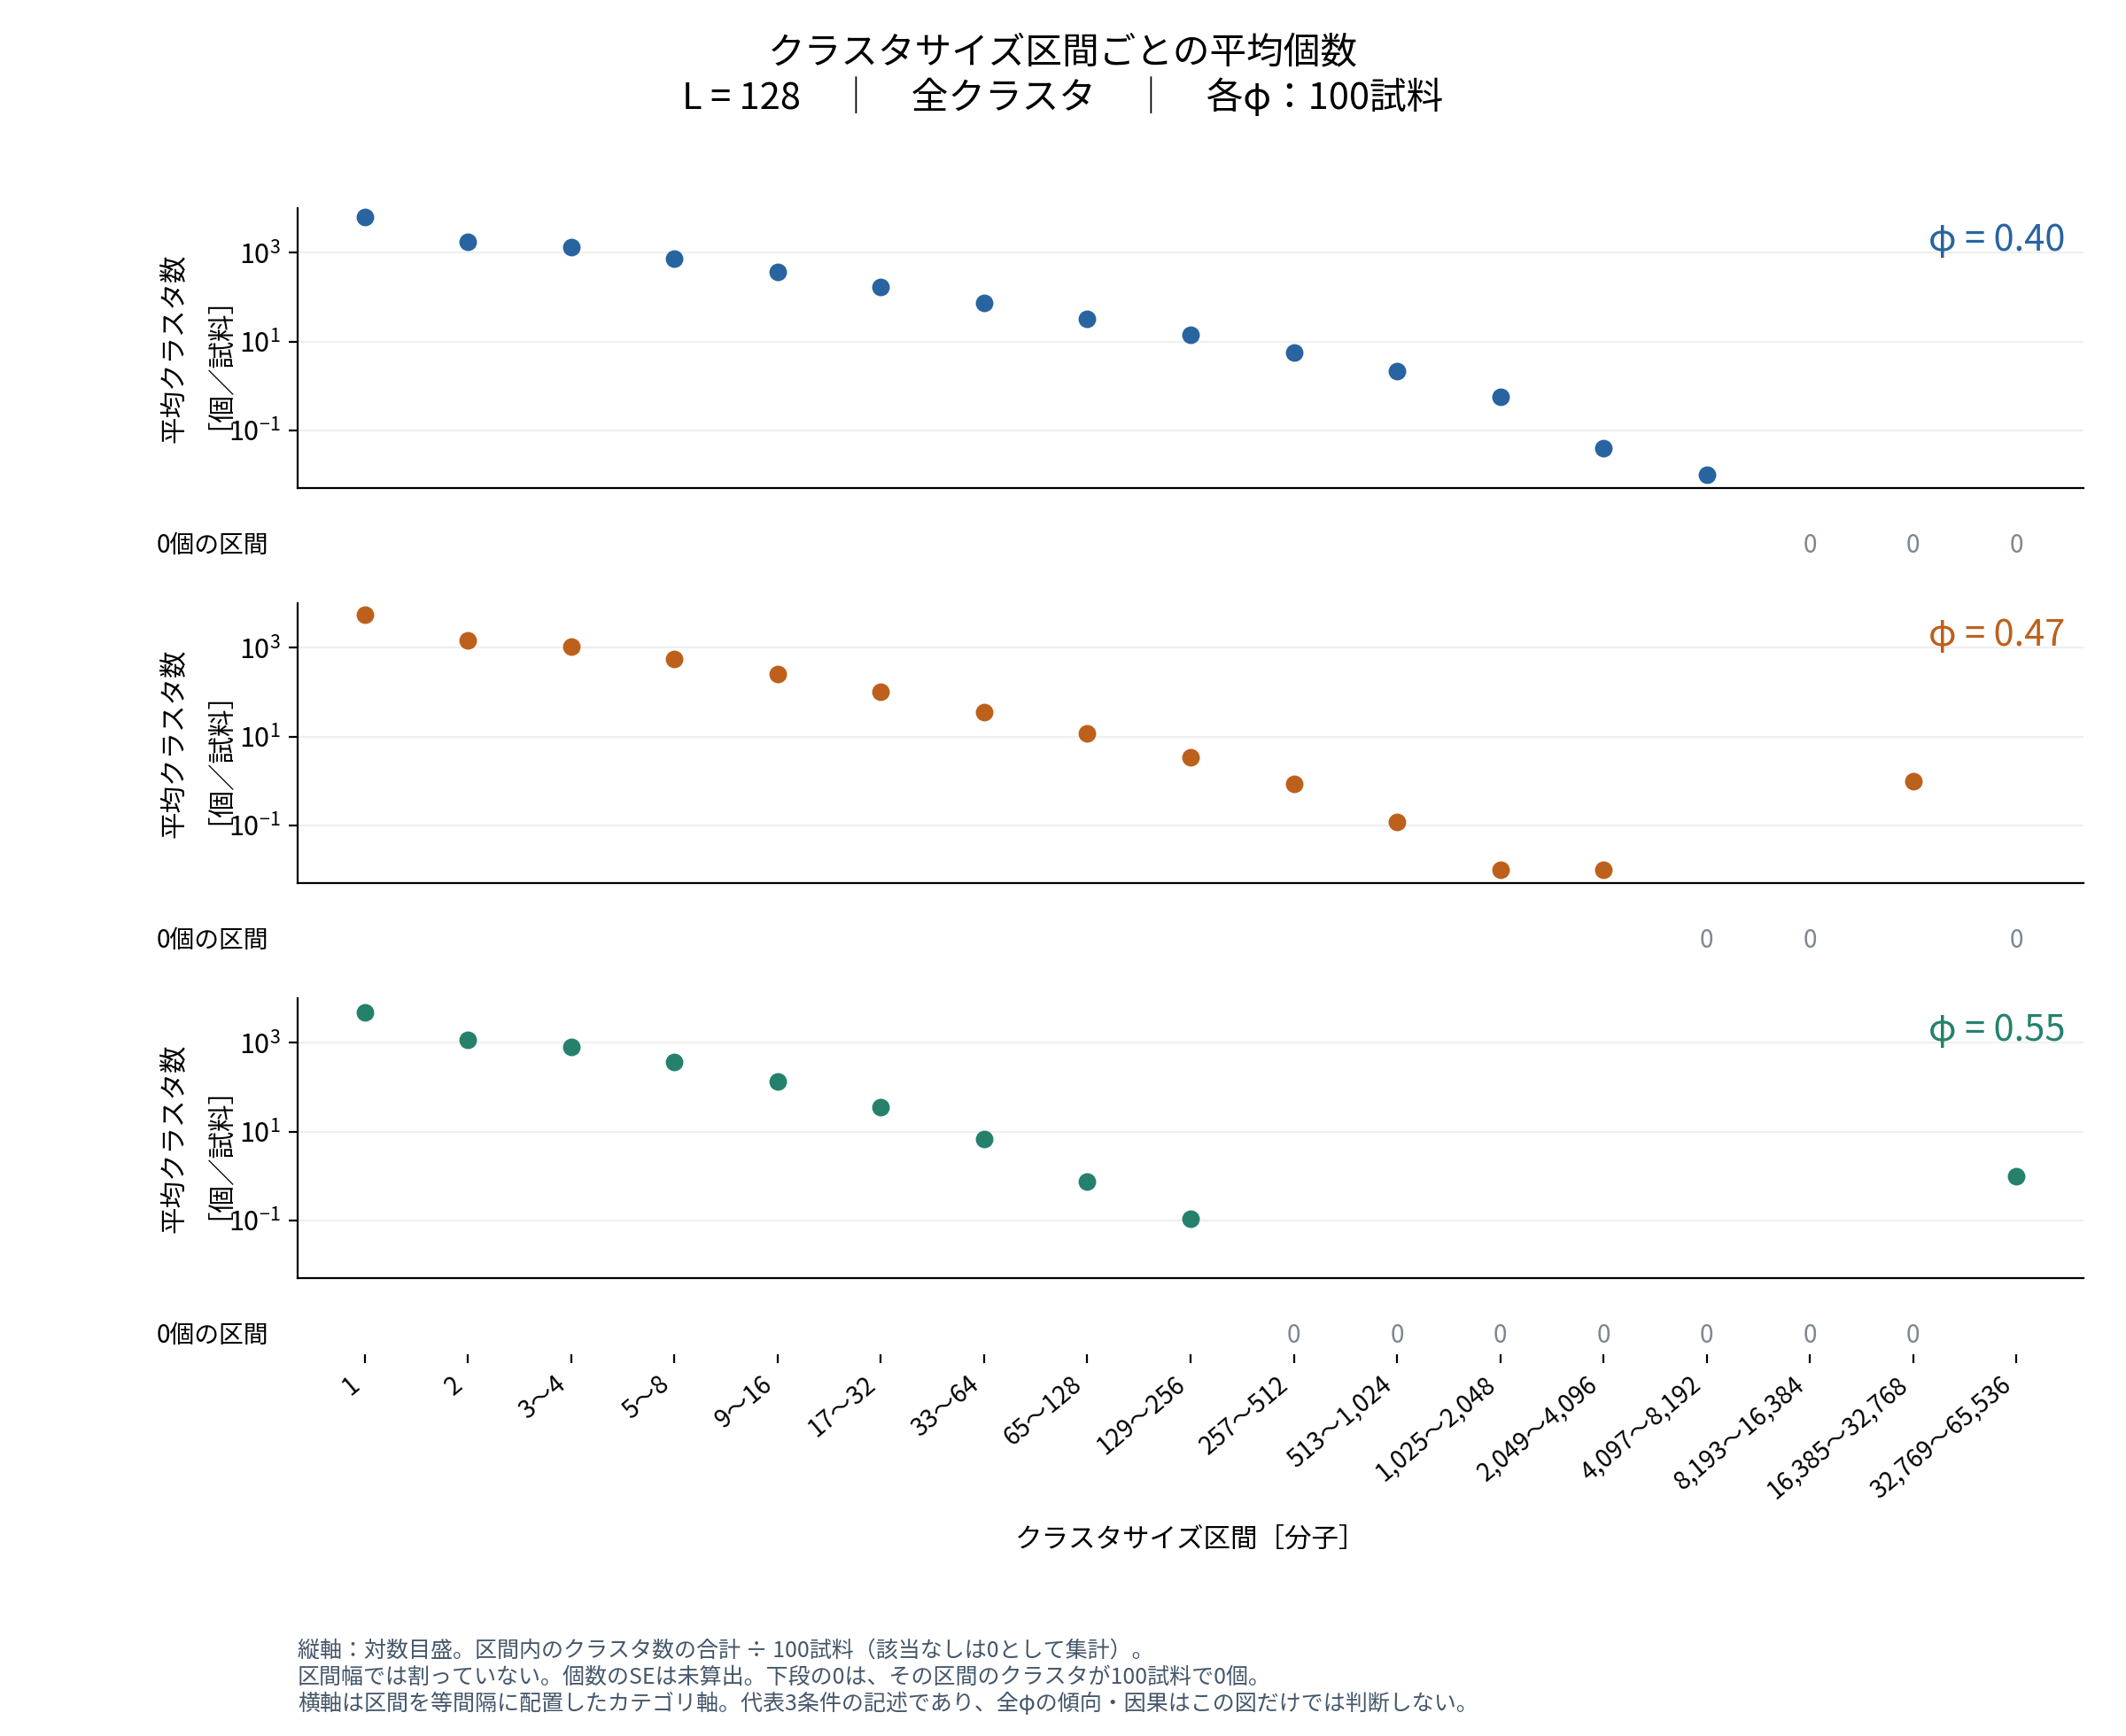

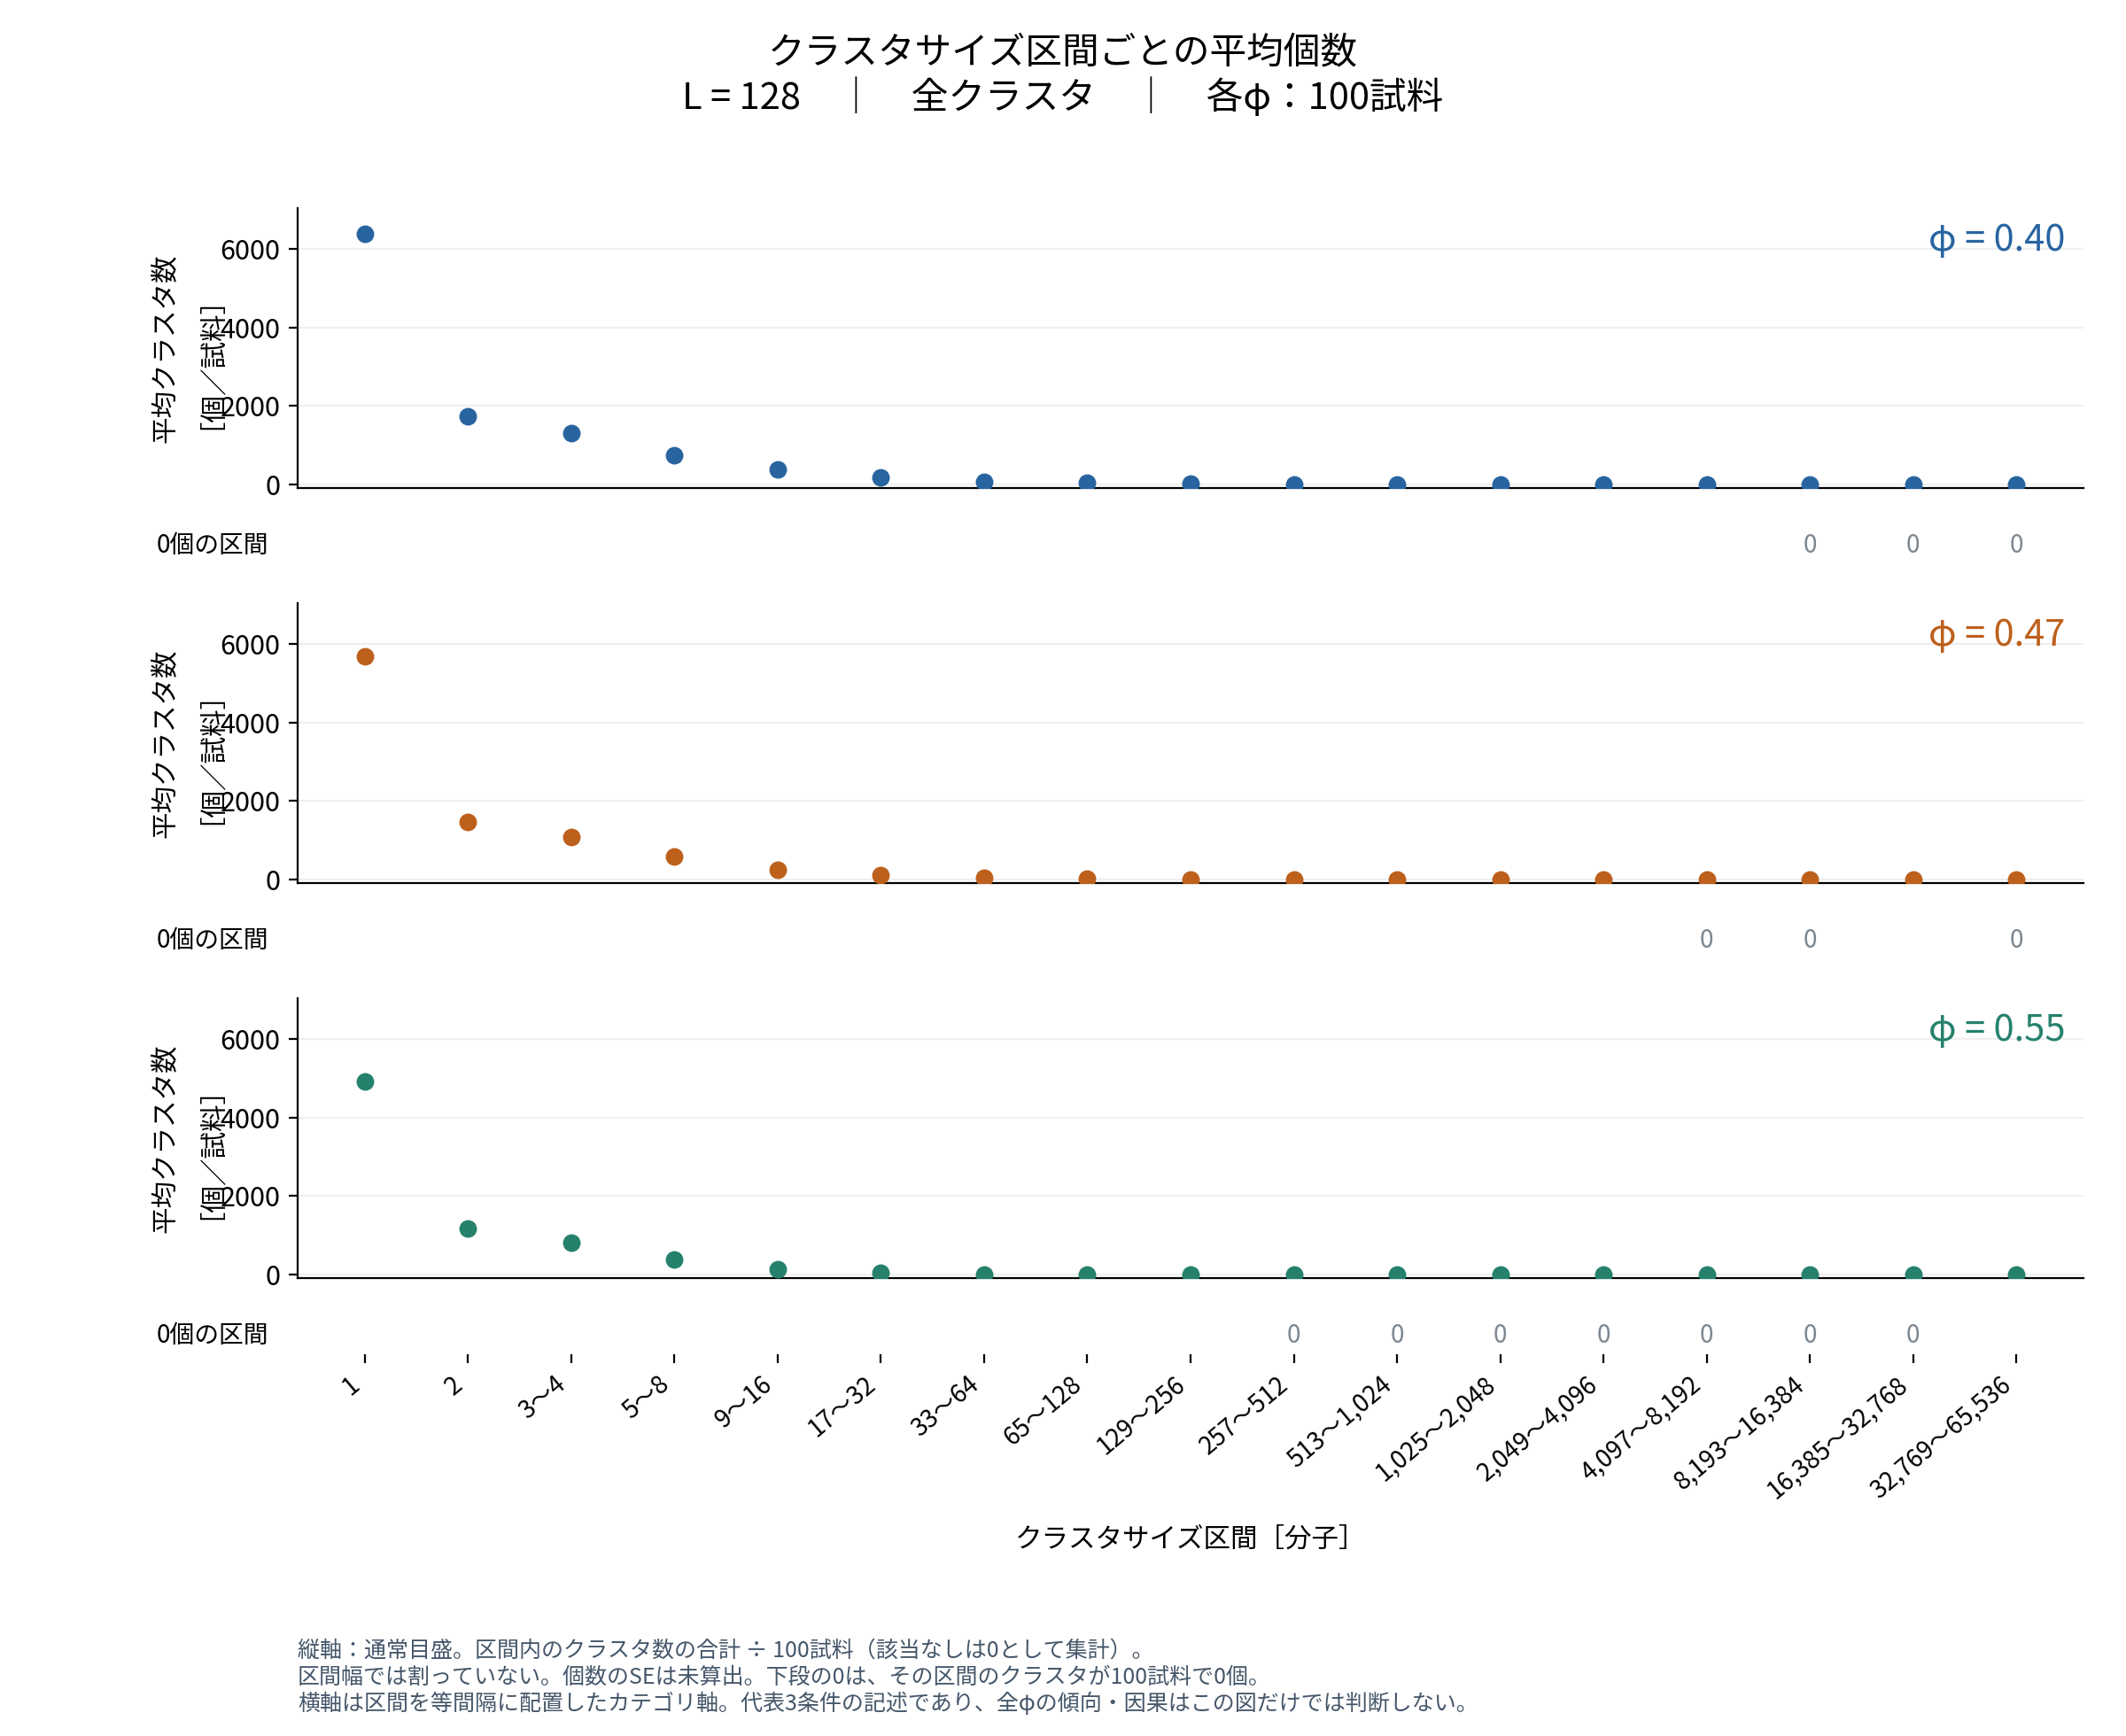

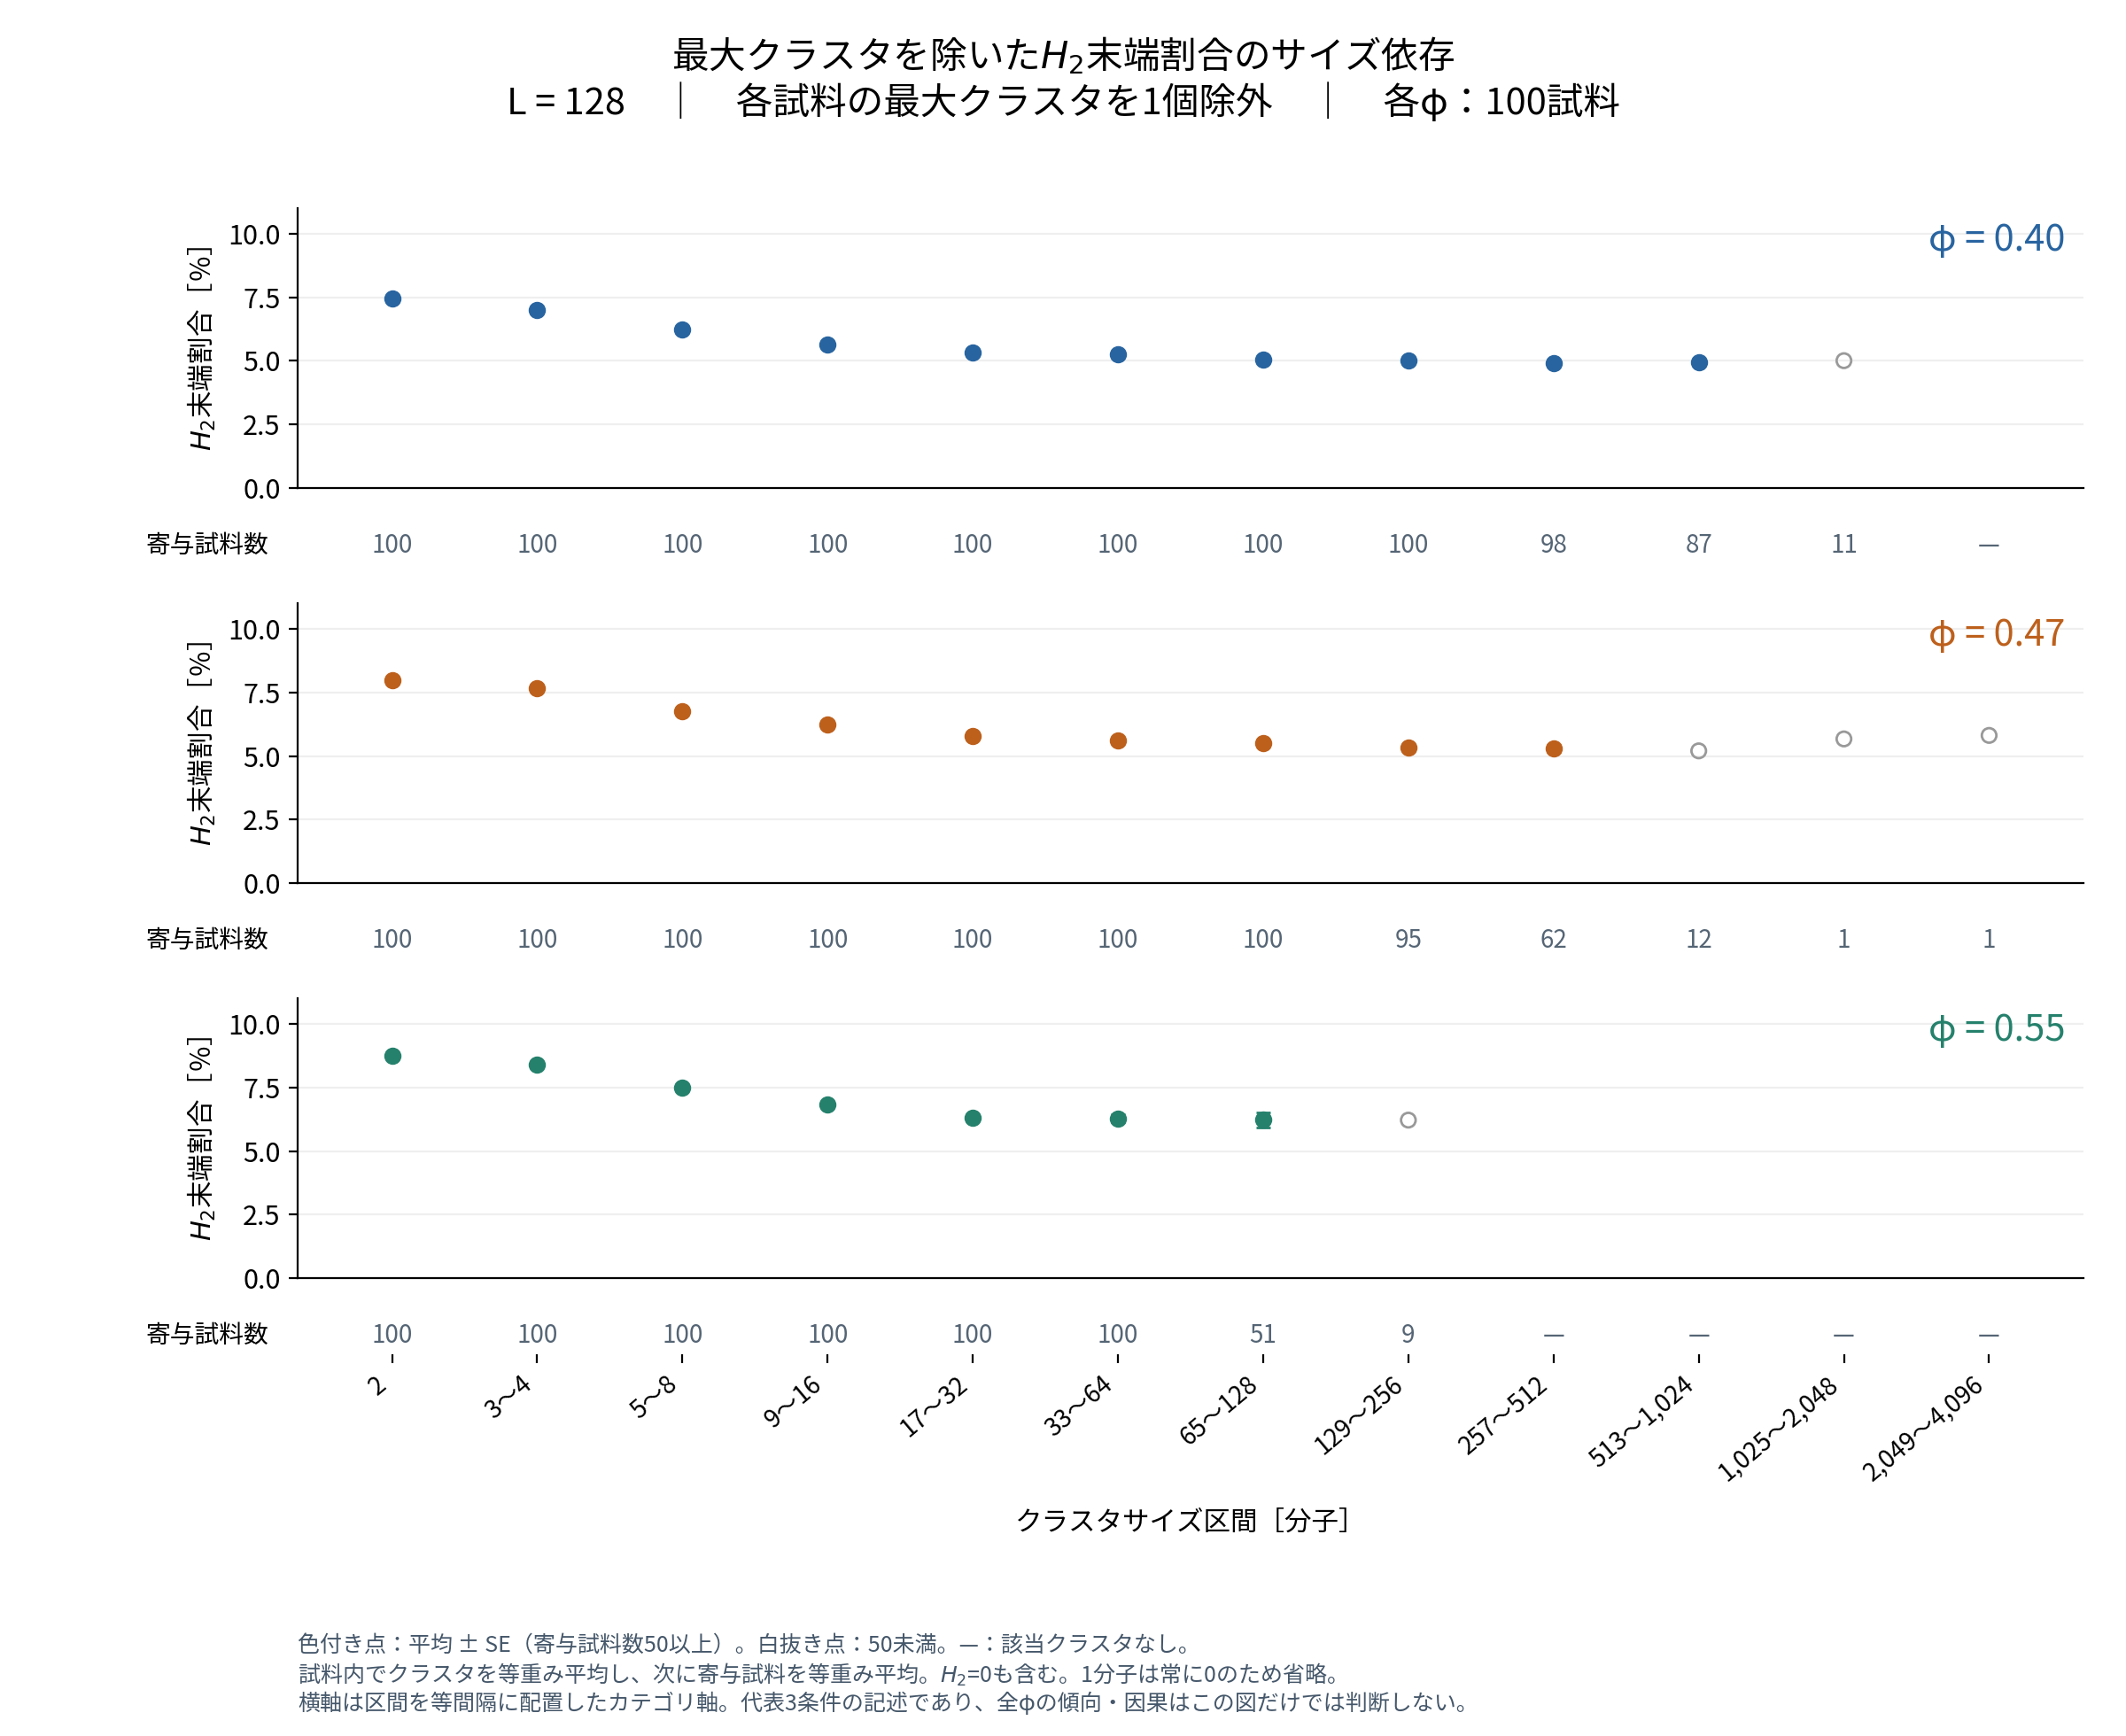

In [ ]:
from IPython.display import display, Image
for name in ["count_log", "count_linear", "h2_fraction"]:
    display(Image(filename=str(ROOT / "figures_colab" / (name + ".png"))))


## 読み方と限界
横軸は等間隔に並べたサイズ区間です。連続量の通常・対数軸ではありません。
クラスタ数は全100試料で平均、H₂割合は区間のある試料だけで平均。H₂=0のクラスタも含みます。
色付き点はn≥50、誤差棒SE。白抜きはn<50。SEは試料間の平均の不確かさです。
代表3条件だけで全φへの一般化やH₂の因果効果は主張しません。Colabの一時領域は永続保存されないため、図はDriveへ保存しています。